In [64]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')

In [65]:
df = sns.load_dataset('titanic')

In [66]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [67]:
df = df.drop(columns= ['who', 'embarked',  'alive', 'pclass', 'parch', 'sibsp', 'deck' ])

In [68]:
df

,survived,sex,age,fare,class,adult_male,embark_town,alone
0,0,male,22.0,7.2500,Third,True,Southampton,False
1,1,female,38.0,71.2833,First,False,Cherbourg,False
2,1,female,26.0,7.9250,Third,False,Southampton,True
3,1,female,35.0,53.1000,First,False,Southampton,False
4,0,male,35.0,8.0500,Third,True,Southampton,True
...,...,...,...,...,...,...,...,...
886,0,male,27.0,13.0000,Second,True,Southampton,True
887,1,female,19.0,30.0000,First,False,Southampton,True
888,0,female,NaN,23.4500,Third,False,Southampton,False
889,1,male,26.0,30.0000,First,True,Cherbourg,True


In [69]:
df.shape

(891, 8)

In [70]:
df.head()

,survived,sex,age,fare,class,adult_male,embark_town,alone
0,0,male,22.0,7.2500,Third,True,Southampton,False
1,1,female,38.0,71.2833,First,False,Cherbourg,False
2,1,female,26.0,7.9250,Third,False,Southampton,True
3,1,female,35.0,53.1000,First,False,Southampton,False
4,0,male,35.0,8.0500,Third,True,Southampton,True


In [71]:
df.isna().sum()

survived         0
sex              0
age            177
fare             0
class            0
adult_male       0
embark_town      2
alone            0
dtype: int64

In [72]:
df.describe()

,survived,age,fare
count,891.000000,714.000000,891.000000
mean,0.383838,29.699118,32.204208
std,0.486592,14.526497,49.693429
min,0.000000,0.420000,0.000000
25%,0.000000,20.125000,7.910400
50%,0.000000,28.000000,14.454200
75%,1.000000,38.000000,31.000000
max,1.000000,80.000000,512.329200


In [73]:
df['survived'].value_counts()

survived
0    549
1    342
Name: count, dtype: int64

In [74]:
df['sex'].value_counts()

sex
male      577
female    314
Name: count, dtype: int64

In [75]:
df['class'].value_counts()

class
Third     491
First     216
Second    184
Name: count, dtype: int64

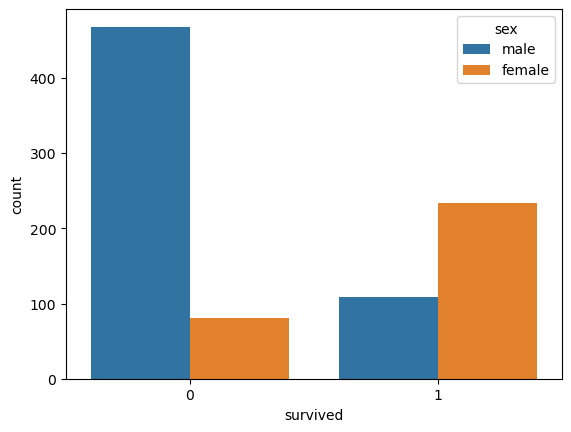

In [76]:
sns.countplot(x = 'survived', hue= 'sex', data =df)
plt.show()

<Axes: xlabel='class', ylabel='count'>

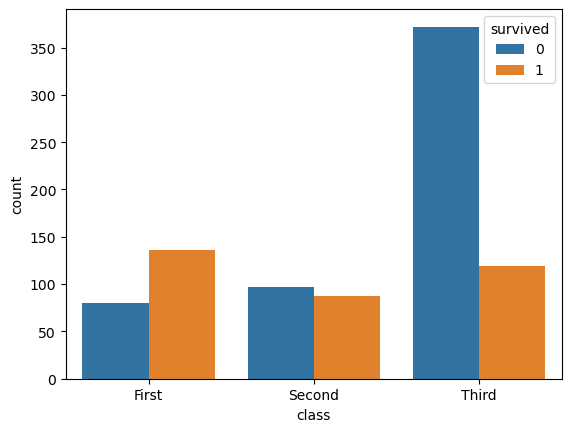

In [77]:
sns.countplot(x = 'class', hue= 'survived', data= df)

In [78]:
y = df['survived']

In [79]:
X = df[['sex', 'age', 'fare', 'class', 'embark_town']]

In [80]:
from sklearn.model_selection import train_test_split


In [81]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.3, random_state=42)

In [82]:
X_train.isna().sum()

sex              0
age            124
fare             0
class            0
embark_town      1
dtype: int64

In [83]:
age_median=  X_train['age'].median()

In [85]:
X_train['age'] = X_train['age'].fillna(age_median)

In [86]:
X_test['age'] = X_test['age'].fillna(age_median)

In [87]:
embark_mode = X_train['embark_town'].mode()[0]

In [90]:
X_train['embark_town'] = X_train['embark_town'].fillna(embark_mode)
X_test['embark_town'] = X_test['embark_town'].fillna(embark_mode)

In [91]:
X_train.isna().sum()
X_test.isna().sum()

sex            0
age            0
fare           0
class          0
embark_town    0
dtype: int64

In [94]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown= 'ignore', sparse_output=False)
cat_col = ['sex', 'class', 'embark_town']

In [95]:
X_train_cat = encoder.fit_transform(X_train[cat_col])
X_test_cat = encoder.transform(X_test[cat_col])

In [97]:
num_cols = ['age', 'fare']

X_train_num = X_train[num_cols].values
X_test_num = X_test[num_cols].values

In [98]:
import numpy as np

X_train_final = np.hstack([X_train_num, X_train_cat])
X_test_final = np.hstack([X_test_num, X_test_cat])

In [100]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(X_train_final, y_train)

,priors,None
,var_smoothing,1e-09


In [101]:
y_pred = model.predict(X_test_final)

In [102]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)

In [ ]:
print